# Section 1 · Task 1.2 — Apply Quantum Operations

**Exam:** C1000-179 *Fundamentals of Quantum Computing Using Qiskit v2.X Developer*
**Section 1:** Perform quantum operations (≈ 16 % of the exam) → **Task 1.2: Apply quantum operations**
**Official references from the study guide:**
- [`circuit_library`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/circuit_library)
- [`qiskit.circuit.QuantumCircuit`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit)

*(Previous notebook: Task 1.1 — Pauli operators. Here the Paulis become gates, and we meet the rest of the gate set.)*

---

### IBM's self-test applied to this task
1. **How** do you apply a gate to a circuit — by method, by gate object, with broadcasting, with controls, inverses and powers?
2. **Why** does each gate exist and how are they related (what is a *global phase*, why are `RZ` and `P` "the same but not equal")?
3. **What happens if you do it wrong?** (wrong control/target order, expecting removed aliases like `qc.cnot` to exist, mixing up control-state bit order …)

### What you will be able to do afterwards
- Apply every standard gate through **both** APIs: `qc.h(0)` and `qc.append(HGate(), [0])`
- Read any gate's **matrix** and verify identities with `Operator.equiv` (equality *up to global phase*)
- Predict exactly which gates **broadcasting** creates
- Build **controlled / inverse / power** versions of gates, including *open* controls (`ctrl_state`)
- Wrap sub-circuits as reusable gates, and apply arbitrary unitaries and library blocks
- Know what changed in Qiskit 2.x (removed aliases, `QFT` → `QFTGate`)

Exercise cells are stubs returning `None`, so the notebook runs end-to-end without your answers. **Solutions are in the last section.**

In [1]:
import warnings
import numpy as np
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector, Pauli
from qiskit.circuit.library import (
    IGate, XGate, YGate, ZGate, HGate, SGate, SdgGate, TGate, TdgGate, SXGate, SXdgGate,
    RXGate, RYGate, RZGate, PhaseGate, UGate, RGate,
    CXGate, CYGate, CZGate, CHGate, CPhaseGate, CRXGate, CRYGate, CRZGate, CUGate,
    SwapGate, iSwapGate, ECRGate, DCXGate, RXXGate, RYYGate, RZZGate, RZXGate,
    CCXGate, CCZGate, CSwapGate, MCXGate, UnitaryGate, PauliGate, QFTGate,
)

np.set_printoptions(precision=3, suppress=True)
print("qiskit", qiskit.__version__)

def _todo(name):
    print(f"⏳ {name}: not attempted yet — fill in the TODO above and re-run this cell.")

def show(M):
    # compact matrix printer
    print(np.array2string(np.asarray(M), precision=3, suppress_small=True))

def describe(sv, tol=1e-9):
    # human-readable sparse listing of a Statevector, e.g. '0.707|00> + 0.707|11>'
    nq = sv.num_qubits
    terms = []
    for k, a in enumerate(sv.data):
        if abs(a) > tol:
            a = complex(np.round(a, 3))
            amp = f"{a.real:g}" if abs(a.imag) < tol else (f"{a.imag:g}i" if abs(a.real) < tol else f"({a:g})")
            terms.append(f"{amp}|{k:0{nq}b}>")
    return " + ".join(terms)

def truth_table(circ):
    # For every computational basis input |q_{n-1}...q_0>, print the output state.
    nq = circ.num_qubits
    for k in range(2 ** nq):
        out = Statevector.from_int(k, 2 ** nq).evolve(circ)
        print(f"  |{k:0{nq}b}>  ->  {describe(out)}")

qiskit 2.6.1


---
## 1 · How a gate gets applied: the `QuantumCircuit` as a list of instructions

A `QuantumCircuit` is an ordered list of **instructions**. Each instruction is
`(operation, qubits, clbits)`. There are two equivalent ways to add one.

| Style | Example | Notes |
|---|---|---|
| **Convenience method** | `qc.cx(0, 1)` | Concise; one method per standard gate; supports **broadcasting** (§5) |
| **Gate object + `append`** | `qc.append(CXGate(), [0, 1])` | Works for *any* gate/instruction (custom, controlled, library blocks); no broadcasting |

Under the hood the first style creates the gate object and appends it for you. Inspect the circuit's `data` to see this.

In [2]:
qc1 = QuantumCircuit(2)
qc1.h(0)
qc1.cx(0, 1)

qc2 = QuantumCircuit(2)
qc2.append(HGate(), [0])
qc2.append(CXGate(), [0, 1])

print("identical unitaries:", Operator(qc1) == Operator(qc2))

# Every entry of qc.data is a CircuitInstruction.
# (In Qiskit 2.x standard gates are "singleton" subclasses, hence class names like _SingletonHGate — they ARE HGate.)
for inst in qc1.data:
    qubit_idx = [qc1.find_bit(q).index for q in inst.qubits]       # Qubit objects -> integer indices
    print(f"operation={inst.operation.name!r:6}  class={type(inst.operation).__name__:8}  qubits={qubit_idx}")

identical unitaries: True
operation='h'     class=_SingletonHGate  qubits=[0]
operation='cx'    class=_SingletonCXGate  qubits=[0, 1]


### Quick circuit metrics you should be able to read off
- `qc.size()` — number of gate operations (barriers excluded)
- `qc.depth()` — length of the longest gate-dependency chain (parallel gates share a layer)
- `qc.width()` — qubits + classical bits
- `qc.count_ops()` — dictionary of operation-name → count

size  : 5
depth : 3
width : 3 (3 qubits + 0 clbits)
ops   : {'h': 3, 'cx': 2}


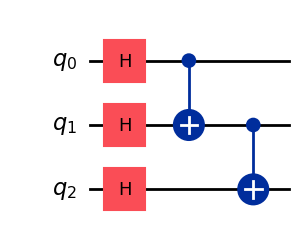

In [3]:
qc = QuantumCircuit(3)
qc.h(0); qc.h(1); qc.h(2)          # 3 gates, all parallel  -> 1 layer
qc.cx(0, 1)                        # layer 2
qc.cx(1, 2)                        # layer 3 (depends on previous cx through qubit 1)
print("size  :", qc.size())
print("depth :", qc.depth())
print("width :", qc.width(), "(3 qubits + 0 clbits)")
print("ops   :", dict(qc.count_ops()))
qc.draw("mpl")

---
## 2 · The single-qubit gate catalogue

### 2.1 Fixed gates

| Method | Class | Matrix | Comment |
|---|---|---|---|
| `qc.id(q)` | `IGate` | $I$ | identity (a timed "do nothing") — **`qc.i` no longer exists** |
| `qc.x(q)` / `y` / `z` | `XGate`… | Paulis | see Task 1.1 |
| `qc.h(q)` | `HGate` | $\tfrac1{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ | creates superposition |
| `qc.s(q)` / `sdg(q)` | `SGate` / `SdgGate` | $\mathrm{diag}(1,i)$ / $\mathrm{diag}(1,-i)$ | $\sqrt Z$ and its inverse |
| `qc.t(q)` / `tdg(q)` | `TGate` / `TdgGate` | $\mathrm{diag}(1,e^{\pm i\pi/4})$ | $\sqrt S$ and its inverse |
| `qc.sx(q)` / `sxdg(q)` | `SXGate` / `SXdgGate` | $\tfrac12\begin{pmatrix}1+i&1-i\\1-i&1+i\end{pmatrix}$ | $\sqrt X$ — a **native IBM hardware gate** |

In [4]:
fixed = [("id", IGate()), ("x", XGate()), ("y", YGate()), ("z", ZGate()), ("h", HGate()),
         ("s", SGate()), ("sdg", SdgGate()), ("t", TGate()), ("tdg", TdgGate()),
         ("sx", SXGate()), ("sxdg", SXdgGate())]
for name, g in fixed:
    print(f"qc.{name}()  ->  {type(g).__name__}")
    show(g.to_matrix())
    print()

qc.id()  ->  _SingletonIGate
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]

qc.x()  ->  _SingletonXGate
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

qc.y()  ->  _SingletonYGate
[[ 0.+0.j -0.-1.j]
 [ 0.+1.j  0.+0.j]]

qc.z()  ->  _SingletonZGate
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]

qc.h()  ->  _SingletonHGate
[[ 0.707+0.j  0.707+0.j]
 [ 0.707+0.j -0.707+0.j]]

qc.s()  ->  _SingletonSGate
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+1.j]]

qc.sdg()  ->  _SingletonSdgGate
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -0.-1.j]]

qc.t()  ->  _SingletonTGate
[[1.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.707+0.707j]]

qc.tdg()  ->  _SingletonTdgGate
[[1.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.707-0.707j]]

qc.sx()  ->  _SingletonSXGate
[[0.5+0.5j 0.5-0.5j]
 [0.5-0.5j 0.5+0.5j]]

qc.sxdg()  ->  _SingletonSXdgGate
[[0.5-0.5j 0.5+0.5j]
 [0.5+0.5j 0.5-0.5j]]



### 2.2 Parameterised single-qubit gates

| Method | Matrix | Geometric meaning |
|---|---|---|
| `qc.rx(θ,q)` | $\begin{pmatrix}\cos\frac\theta2&-i\sin\frac\theta2\\-i\sin\frac\theta2&\cos\frac\theta2\end{pmatrix}$ | rotate by $\theta$ about **X** |
| `qc.ry(θ,q)` | $\begin{pmatrix}\cos\frac\theta2&-\sin\frac\theta2\\\sin\frac\theta2&\cos\frac\theta2\end{pmatrix}$ | rotate about **Y** (real matrix) |
| `qc.rz(θ,q)` | $\mathrm{diag}(e^{-i\theta/2},\,e^{i\theta/2})$ | rotate about **Z** |
| `qc.p(λ,q)` | $\mathrm{diag}(1,\,e^{i\lambda})$ | **phase** gate (only the $\lvert1\rangle$ component is rotated) |
| `qc.u(θ,φ,λ,q)` | $\begin{pmatrix}\cos\frac\theta2&-e^{i\lambda}\sin\frac\theta2\\e^{i\varphi}\sin\frac\theta2&e^{i(\varphi+\lambda)}\cos\frac\theta2\end{pmatrix}$ | the **most general** single-qubit unitary (up to nothing — it is exact) |
| `qc.r(θ,φ,q)` | rotation by $\theta$ about the axis at angle $\varphi$ in the XY-plane | $R(\theta,0)=R_X(\theta)$, $R(\theta,\pi/2)=R_Y(\theta)$ |

> **Removed in Qiskit 2.x:** `qc.u1`, `qc.u2`, `qc.u3` (use `p`, `u`), and `cu1`/`cu3` (use `cp`, `cu`). If an old tutorial uses them, translate: `u1(λ)=p(λ)`, `u3(θ,φ,λ)=u(θ,φ,λ)`.

Verify the matrix formulas by building them by hand:

In [5]:
th, ph, lam = 0.9, 0.5, 1.3
c, s = np.cos(th / 2), np.sin(th / 2)

hand = {
  "rx": np.array([[c, -1j * s], [-1j * s, c]]),
  "ry": np.array([[c, -s], [s, c]]),
  "rz": np.diag([np.exp(-1j * th / 2), np.exp(1j * th / 2)]),
  "p" : np.diag([1, np.exp(1j * th)]),
  "u" : np.array([[c, -np.exp(1j * lam) * s], [np.exp(1j * ph) * s, np.exp(1j * (ph + lam)) * c]]),
}
lib = {"rx": RXGate(th), "ry": RYGate(th), "rz": RZGate(th), "p": PhaseGate(th), "u": UGate(th, ph, lam)}
for k in hand:
    print(f"{k:>2}: hand-built formula == Qiskit gate ?", np.allclose(hand[k], lib[k].to_matrix()))

# R gate: R(theta, 0) = RX(theta), R(theta, pi/2) = RY(theta)
print("R(θ,0)   == RX(θ):", np.allclose(RGate(th, 0).to_matrix(),          RXGate(th).to_matrix()))
print("R(θ,π/2) == RY(θ):", np.allclose(RGate(th, np.pi / 2).to_matrix(),  RYGate(th).to_matrix()))

rx: hand-built formula == Qiskit gate ? True
ry: hand-built formula == Qiskit gate ? True
rz: hand-built formula == Qiskit gate ? True
 p: hand-built formula == Qiskit gate ? True
 u: hand-built formula == Qiskit gate ? True
R(θ,0)   == RX(θ): True
R(θ,π/2) == RY(θ): True


---
## 3 · Relationships between gates — and the global-phase subtlety

### 3.1 Equality *up to global phase*
Two unitaries $U$ and $e^{i\gamma}U$ produce **identical measurement statistics and identical expectation values** for every input, so physically they are the same operation. Qiskit gives you both notions:

| Test | Meaning |
|---|---|
| `Operator(a) == Operator(b)` | **exactly** the same matrix |
| `Operator(a).equiv(Operator(b))` | same matrix **up to a global phase** |

Use `equiv` when you ask "do these circuits implement the same *physics*?", and `==` when you need the literal matrix (e.g. when you will later **control** the gate — a global phase becomes a *relative* phase once controlled!).

### 3.2 Identities worth knowing — each verified, not asserted

In [6]:
def same(a, b):
    # Return (exactly equal, equal up to global phase) for two circuits / gates.
    A, B = Operator(a), Operator(b)
    return (np.allclose(A.data, B.data), A.equiv(B))

def circ(*ops, nq=1):
    # build a circuit from (gate_object, [qubits]) pairs
    qc = QuantumCircuit(nq)
    for g, qs in ops:
        qc.append(g, qs)
    return qc

checks = {
  "S·S  = Z"                : (circ((SGate(),[0]), (SGate(),[0])),              ZGate()),
  "T·T  = S"                : (circ((TGate(),[0]), (TGate(),[0])),              SGate()),
  "SX·SX = X"               : (circ((SXGate(),[0]), (SXGate(),[0])),            XGate()),
  "H·H  = I"                : (circ((HGate(),[0]), (HGate(),[0])),              IGate()),
  "H·Z·H = X"               : (circ((HGate(),[0]), (ZGate(),[0]), (HGate(),[0])), XGate()),
  "H·X·H = Z"               : (circ((HGate(),[0]), (XGate(),[0]), (HGate(),[0])), ZGate()),
  "S·Sdg = I"               : (circ((SGate(),[0]), (SdgGate(),[0])),            IGate()),
  "U(π,0,π) = X"            : (UGate(np.pi, 0, np.pi),                          XGate()),
  "U(π/2,0,π) = H"          : (UGate(np.pi / 2, 0, np.pi),                      HGate()),
  "P(π) = Z"                : (PhaseGate(np.pi),                                ZGate()),
  "P(π/2) = S"              : (PhaseGate(np.pi / 2),                            SGate()),
  "RX(π) = X"               : (RXGate(np.pi),                                   XGate()),
  "RZ(π) = Z"               : (RZGate(np.pi),                                   ZGate()),
  "RZ(θ) = P(θ)"            : (RZGate(0.8),                                     PhaseGate(0.8)),
}
print(f"{'identity':<16} {'exactly equal':>14} {'equal up to global phase':>26}")
for name, (a, b) in checks.items():
    exact, up_to = same(a, b)
    print(f"{name:<16} {str(exact):>14} {str(up_to):>26}")

identity          exactly equal   equal up to global phase
S·S  = Z                   True                       True
T·T  = S                   True                       True
SX·SX = X                  True                       True
H·H  = I                   True                       True
H·Z·H = X                  True                       True
H·X·H = Z                  True                       True
S·Sdg = I                  True                       True
U(π,0,π) = X               True                       True
U(π/2,0,π) = H             True                       True
P(π) = Z                   True                       True
P(π/2) = S                 True                       True
RX(π) = X                 False                       True
RZ(π) = Z                 False                       True
RZ(θ) = P(θ)              False                       True


**Read the pattern.** Most identities hold *exactly*. The three that differ are exactly the ones comparing **rotations** to **named gates**:

- `RX(π)` $=-iX$,  `RZ(π)` $=-iZ$  (an overall factor of $-i$)
- `RZ(θ)` $=e^{-i\theta/2}\,P(\theta)$

The rotation gates are *defined* to be $e^{-i\theta P/2}$ (symmetric, determinant 1), while `P`, `S`, `T`, `Z` keep $|0\rangle$ fixed. They differ only by a global phase — physically the same, but **not** `==`. This is *the* classic exam distinction between `RZ` and `P`.

In [7]:
# Measure the exact factor between RZ(θ) and P(θ)
theta = 0.8
ratio = RZGate(theta).to_matrix()[0, 0] / PhaseGate(theta).to_matrix()[0, 0]
print("RZ(θ) = factor · P(θ), factor =", np.round(ratio, 4), " vs  e^{-iθ/2} =", np.round(np.exp(-1j * theta / 2), 4))

# A circuit can *carry* a global phase explicitly
qc = QuantumCircuit(1)
qc.rz(theta, 0)
qc.global_phase = theta / 2                # compensate: now it equals P(θ) exactly
print("RZ + global_phase(θ/2) == P(θ) exactly:", np.allclose(Operator(qc).data, PhaseGate(theta).to_matrix()))

RZ(θ) = factor · P(θ), factor = (0.9211-0.3894j)  vs  e^{-iθ/2} = (0.9211-0.3894j)
RZ + global_phase(θ/2) == P(θ) exactly: True


### 3.3 Why global phase matters once you *control* a gate
`Z` and `RZ(π)` differ by $-i$. Control each on qubit 0 and the "global" phase becomes a *relative* phase between control $=0$ and control $=1$ — now observable:

In [8]:
cz_exact  = ZGate().control(1)
crz_pi    = RZGate(np.pi).control(1)
print("Z and RZ(π) equal up to phase    :", Operator(ZGate()).equiv(Operator(RZGate(np.pi))))
print("controlled-Z vs controlled-RZ(π) equal up to phase:", Operator(cz_exact).equiv(Operator(crz_pi)), "   <- different physics!")
print("\ncontrolled-RZ(π) diagonal:", np.round(np.diag(Operator(crz_pi).data), 3), "  (the |1> control branch picks up -i, |0> branch does not)")

Z and RZ(π) equal up to phase    : True
controlled-Z vs controlled-RZ(π) equal up to phase: False    <- different physics!

controlled-RZ(π) diagonal: [1.+0.j 0.-1.j 1.+0.j 0.+1.j]   (the |1> control branch picks up -i, |0> branch does not)


---
## 4 · Multi-qubit gates and the control/target convention

### 4.1 The catalogue

| Method | Class | Action |
|---|---|---|
| `qc.cx(c, t)` | `CXGate` | flip target if control is 1 |
| `qc.cy(c, t)`, `qc.cz(c, t)`, `qc.ch(c, t)` | `CYGate`… | controlled-Y / Z / H |
| `qc.cp(λ, c, t)` | `CPhaseGate` | phase $e^{i\lambda}$ on $\lvert11\rangle$ only (symmetric in its qubits) |
| `qc.crx/cry/crz(θ, c, t)` | `CRXGate`… | controlled rotations |
| `qc.cu(θ,φ,λ,γ, c, t)` | `CUGate` | controlled-U with extra global-phase parameter $\gamma$ |
| `qc.swap(a, b)` | `SwapGate` | exchange two qubits |
| `qc.iswap(a, b)` | `iSwapGate` | swap with an extra $i$ on the swapped terms |
| `qc.ecr(a, b)`, `qc.dcx(a, b)` | `ECRGate`, `DCXGate` | echoed cross-resonance (IBM native on some devices), double-CX |
| `qc.rxx/ryy/rzz/rzx(θ, a, b)` | `RXXGate`… | two-qubit rotations $e^{-i\theta\,P\otimes Q/2}$ |
| `qc.ccx(c1, c2, t)` | `CCXGate` | **Toffoli** — flip target if both controls are 1 |
| `qc.ccz(a, b, c)` | `CCZGate` | phase flip on $\lvert111\rangle$ (symmetric) |
| `qc.cswap(c, a, b)` | `CSwapGate` | **Fredkin** — swap $a,b$ if control is 1 |
| `qc.mcx(controls, t)` | `MCXGate` | multi-controlled X with any number of controls |

> **Removed aliases in 2.x:** `qc.cnot`, `qc.toffoli`, `qc.fredkin` — use `cx`, `ccx`, `cswap`.

### 4.2 The ordering convention you must get right
In `qc.cx(control, target)` the **first argument is the control**. In matrix form (little-endian, basis order $|q_1q_0\rangle$ = 00, 01, 10, 11):

- `cx(0, 1)` — control = qubit 0 → swaps $|01\rangle\leftrightarrow|11\rangle$
- `cx(1, 0)` — control = qubit 1 → swaps $|10\rangle\leftrightarrow|11\rangle$

Truth tables make this unambiguous:

In [9]:
qa = QuantumCircuit(2); qa.cx(0, 1)
qb = QuantumCircuit(2); qb.cx(1, 0)

print("cx(0, 1)   control = q0, target = q1")
truth_table(qa)
print("\ncx(1, 0)   control = q1, target = q0")
truth_table(qb)
print("\nmatrix of cx(0,1):"); show(Operator(qa).data.real)

cx(0, 1)   control = q0, target = q1
  |00>  ->  1|00>
  |01>  ->  1|11>
  |10>  ->  1|10>
  |11>  ->  1|01>

cx(1, 0)   control = q1, target = q0
  |00>  ->  1|00>
  |01>  ->  1|01>
  |10>  ->  1|11>
  |11>  ->  1|10>

matrix of cx(0,1):
[[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]]


### 4.3 Symmetric vs directional gates
`CZ`, `CP`, `SWAP`, `iSWAP`, `RZZ`, `CCZ` do **not** care which qubit you call "control" — swapping arguments gives the same unitary. `CX`, `CY`, `CH`, `CRX…` are directional. And a classic trick reverses a CX direction with Hadamards:
$\text{CX}(1,0)=(H\otimes H)\,\text{CX}(0,1)\,(H\otimes H)$.

In [10]:
def two(gate, a, b):
    qc = QuantumCircuit(2); qc.append(gate, [a, b]); return qc

print("cz(0,1)   == cz(1,0)  :", Operator(two(CZGate(), 0, 1)) == Operator(two(CZGate(), 1, 0)))
print("cp(λ)     symmetric   :", Operator(two(CPhaseGate(0.7), 0, 1)) == Operator(two(CPhaseGate(0.7), 1, 0)))
print("swap      symmetric   :", Operator(two(SwapGate(), 0, 1)) == Operator(two(SwapGate(), 1, 0)))
print("rzz       symmetric   :", Operator(two(RZZGate(0.7), 0, 1)) == Operator(two(RZZGate(0.7), 1, 0)))
print("cx(0,1)   == cx(1,0)  :", Operator(two(CXGate(), 0, 1)) == Operator(two(CXGate(), 1, 0)), "  <- directional!")

# CX direction reversal with Hadamards
rev = QuantumCircuit(2)
rev.h([0, 1]); rev.cx(0, 1); rev.h([0, 1])
print("(H⊗H) CX(0,1) (H⊗H) == CX(1,0):", Operator(rev) == Operator(two(CXGate(), 1, 0)))

# CNOT from CZ: conjugate the target with H
cx_from_cz = QuantumCircuit(2); cx_from_cz.h(1); cx_from_cz.cz(0, 1); cx_from_cz.h(1)
print("H(t)·CZ·H(t) == CX(c→t)       :", Operator(cx_from_cz) == Operator(two(CXGate(), 0, 1)))

cz(0,1)   == cz(1,0)  : True
cp(λ)     symmetric   : True
swap      symmetric   : True
rzz       symmetric   : True
cx(0,1)   == cx(1,0)  : False   <- directional!
(H⊗H) CX(0,1) (H⊗H) == CX(1,0): True
H(t)·CZ·H(t) == CX(c→t)       : True


### 4.4 Three-qubit gates
Toffoli (`ccx`) and Fredkin (`cswap`) — the classical-reversible-computing workhorses.

In [11]:
print("ccx(0, 1, 2): controls q0,q1 ; target q2   (flips only |111> <-> |011>)")
t = QuantumCircuit(3); t.ccx(0, 1, 2)
truth_table(t)
print("\ncswap(0, 1, 2): control q0 ; swaps q1,q2   (acts only when q0=1)")
f = QuantumCircuit(3); f.cswap(0, 1, 2)
truth_table(f)

ccx(0, 1, 2): controls q0,q1 ; target q2   (flips only |111> <-> |011>)
  |000>  ->  1|000>
  |001>  ->  1|001>
  |010>  ->  1|010>
  |011>  ->  1|111>
  |100>  ->  1|100>
  |101>  ->  1|101>
  |110>  ->  1|110>
  |111>  ->  1|011>

cswap(0, 1, 2): control q0 ; swaps q1,q2   (acts only when q0=1)
  |000>  ->  1|000>
  |001>  ->  1|001>
  |010>  ->  1|010>
  |011>  ->  1|101>
  |100>  ->  1|100>
  |101>  ->  1|011>
  |110>  ->  1|110>
  |111>  ->  1|111>


---
## 5 · Broadcasting — one call, many gates

Convenience methods accept **lists/ranges** and expand them into several gates.

**Rules**
1. **Single-qubit gate + list** → one gate per qubit: `qc.h([0,1,2])` ≡ `h(0), h(1), h(2)`.
2. **Two-qubit gate, two lists of equal length** → pair them **element-wise** (`zip`): `qc.cx([0,1],[2,3])` ≡ `cx(0,2), cx(1,3)`.
3. **Two-qubit gate, one scalar + one list** → the scalar is **repeated**: `qc.cx(0,[1,2])` ≡ `cx(0,1), cx(0,2)`.
4. **Lists of unequal length** (both longer than 1) → `CircuitError`.
5. **Three-or-more-qubit gates** (`ccx`, `cswap`, `mcx` …) have only limited broadcasting; don't rely on it — loop instead.
6. Parameters broadcast too: `qc.rx(0.3, range(2))` applies the *same* angle to qubits 0 and 1.

(`QuantumCircuit.append` does **not** broadcast; it takes exactly the qubits for one instruction.)

In [12]:
def ops(qc):
    return [(i.operation.name, tuple(qc.find_bit(q).index for q in i.qubits)) for i in qc.data]

qc = QuantumCircuit(5)
qc.h([0, 1, 2])
print("h([0,1,2])           ->", ops(qc)); qc.clear()

qc.cx([0, 1], [2, 3])
print("cx([0,1],[2,3])      ->", ops(qc)); qc.clear()

qc.cx(0, [1, 2, 3])
print("cx(0,[1,2,3])        ->", ops(qc)); qc.clear()

qc.rx(0.3, range(2))
print("rx(0.3, range(2))    ->", ops(qc)); qc.clear()

try:
    qc.cx([0, 1, 2], [3, 4])
except Exception as e:
    print("cx([0,1,2],[3,4])    -> CircuitError  (unequal list lengths)")

try:
    qc.ccx(0, 1, [2, 3])
except Exception as e:
    print("ccx(0,1,[2,3])       -> CircuitError  (3-qubit gates don't broadcast like this)")

h([0,1,2])           -> [('h', (0,)), ('h', (1,)), ('h', (2,))]
cx([0,1],[2,3])      -> [('cx', (0, 2)), ('cx', (1, 3))]
cx(0,[1,2,3])        -> [('cx', (0, 1)), ('cx', (0, 2)), ('cx', (0, 3))]
rx(0.3, range(2))    -> [('rx', (0,)), ('rx', (1,))]
cx([0,1,2],[3,4])    -> CircuitError  (unequal list lengths)
ccx(0,1,[2,3])       -> CircuitError  (3-qubit gates don't broadcast like this)


---
## 6 · Transforming gates: `control`, `inverse`, `power`

Every `Gate` object can be transformed. This is the systematic way to get gates that have no dedicated method.

| Call | Result |
|---|---|
| `gate.inverse()` | the adjoint gate $U^\dagger$ (`S` → `Sdg`, `RX(θ)` → `RX(-θ)`, `SX` → `SXdg`) |
| `gate.power(k)` | $U^k$ (works for non-integer $k$ too, via matrix power) |
| `gate.control(n)` | add `n` control qubits (**controls come first** in the qubit list) |
| `gate.control(n, ctrl_state=…)` | **open / mixed controls** — the gate fires on a specific control bit-pattern |
| `qc.inverse()` | reverse a whole circuit (each gate inverted, order reversed) |

In [13]:
print("S.inverse()          :", SGate().inverse().name)
print("T.inverse()          :", TGate().inverse().name)
print("SX.inverse()         :", SXGate().inverse().name)
print("RX(0.3).inverse()    :", RXGate(0.3).inverse().name, RXGate(0.3).inverse().params)
print("S.power(2) == Z      :", np.allclose(SGate().power(2).to_matrix(), ZGate().to_matrix()))
print("X.power(0.5) == SX ? :", np.allclose(XGate().power(0.5).to_matrix(), SXGate().to_matrix()),
      "(up to the principal square root convention)")

# Controlled versions get conventional names when they exist
print("\nXGate().control(1)    ->", XGate().control(1).name)
print("XGate().control(2)    ->", XGate().control(2).name, "(Toffoli!)")
print("ZGate().control(1)    ->", ZGate().control(1).name)
print("HGate().control(1)    ->", HGate().control(1).name)
print("XGate().control(3)    ->", XGate().control(3).name)

S.inverse()          : sdg
T.inverse()          : tdg
SX.inverse()         : sxdg
RX(0.3).inverse()    : rx [-0.3]
S.power(2) == Z      : True


X.power(0.5) == SX ? : True (up to the principal square root convention)

XGate().control(1)    -> cx
XGate().control(2)    -> ccx (Toffoli!)
ZGate().control(1)    -> cz
HGate().control(1)    -> ch
XGate().control(3)    -> mcx


### 6.1 Open controls with `ctrl_state`
`ctrl_state` says which control pattern triggers the gate. As an **integer** or a **bit-string** it is read like a Qiskit basis state: **the rightmost bit corresponds to the first control qubit** (little-endian again!).

For `XGate().control(2, ctrl_state=...)` with controls on qubits `[0, 1]` and target on qubit 2:

| `ctrl_state` | triggers when (q1, q0) = |
|---|---|
| `"11"` or `3` (default) | (1, 1) |
| `"01"` or `1` | q1 = **0**, q0 = **1** |
| `"10"` or `2` | q1 = **1**, q0 = **0** |
| `"00"` or `0` | (0, 0) |

In [14]:
# Fire only when q0 = 1 and q1 = 0  -> ctrl_state = "01" (string reads q1 q0)
g = XGate().control(2, ctrl_state="01")
qc = QuantumCircuit(3)
qc.append(g, [0, 1, 2])           # controls first, then target
print("gate name:", g.name, "| ctrl_state:", g.ctrl_state)
print("inputs |q2 q1 q0>; only the row with q1=0,q0=1 flips the target:")
truth_table(qc)

gate name: ccx_o1 | ctrl_state: 1
inputs |q2 q1 q0>; only the row with q1=0,q0=1 flips the target:
  |000>  ->  1|000>
  |001>  ->  1|101>
  |010>  ->  1|010>
  |011>  ->  1|011>
  |100>  ->  1|100>
  |101>  ->  1|001>
  |110>  ->  1|110>
  |111>  ->  1|111>


In [15]:
# Open-controlled-X on a single control: act when control is |0>
open_cx = XGate().control(1, ctrl_state=0)
qc = QuantumCircuit(2); qc.append(open_cx, [0, 1])
print("control-on-0 X (target q1, control q0):")
truth_table(qc)

# Equivalent hand-built version: X · CX · X on the control
sandwich = QuantumCircuit(2); sandwich.x(0); sandwich.cx(0, 1); sandwich.x(0)
print("\nsandwich X·CX·X equals it:", Operator(sandwich) == Operator(qc))

control-on-0 X (target q1, control q0):
  |00>  ->  1|10>
  |01>  ->  1|01>
  |10>  ->  1|00>
  |11>  ->  1|11>

sandwich X·CX·X equals it: True


---
## 7 · Reusable operations: `to_gate`, `compose`, `append`, `inverse`, `repeat`

| Tool | Purpose |
|---|---|
| `sub.to_gate(label=…)` | freeze a **unitary** sub-circuit into a single `Gate` (can then be controlled, inverted, powered) |
| `sub.to_instruction()` | like `to_gate` but may include measurements / resets (not a unitary `Gate`, **cannot be controlled**) |
| `qc.append(op, qubits)` | add an instruction **as a box** (stays one named instruction until you `decompose`) |
| `qc.compose(other, qubits=…)` | splice `other`'s **gates directly in** (flat, no box) |
| `qc.decompose()` | expand boxes one level |
| `qc.inverse()` / `qc.repeat(k)` | reverse / repeat a circuit |

type: Gate | name: bell
big.count_ops()               : {'bell': 2}   <- two boxed 'bell' instructions


big.decompose().count_ops()   : {'h': 2, 'cx': 2}
controlled version: cbell with 3 qubits


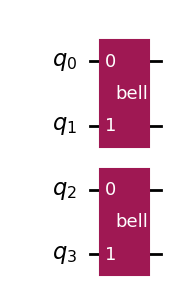

In [16]:
# Build a Bell-pair *gate*
bell_sub = QuantumCircuit(2, name="bell")
bell_sub.h(0)
bell_sub.cx(0, 1)
bell_gate = bell_sub.to_gate()
print("type:", type(bell_gate).__name__, "| name:", bell_gate.name)

# Use it twice, on different qubit pairs, inside a bigger circuit
big = QuantumCircuit(4)
big.append(bell_gate, [0, 1])
big.append(bell_gate, [2, 3])
print("big.count_ops()               :", dict(big.count_ops()), "  <- two boxed 'bell' instructions")
print("big.decompose().count_ops()   :", dict(big.decompose().count_ops()))

# Gates can be controlled / inverted like built-ins
cbell = bell_gate.control(1)
print("controlled version:", cbell.name, "with", cbell.num_qubits, "qubits")
big.draw("mpl")

In [17]:
# append (boxed)  vs  compose (flat)
a = QuantumCircuit(2); a.h(0)
b = QuantumCircuit(1, name="XZ"); b.x(0); b.z(0)

boxed = a.copy(); boxed.append(b.to_gate(), [1])
flat  = a.compose(b, qubits=[1])
print("append -> ", ops(boxed))
print("compose-> ", ops(flat))
print("same unitary:", Operator(boxed) == Operator(flat))

# inverse / repeat
circ_u = QuantumCircuit(2); circ_u.h(0); circ_u.cx(0, 1); circ_u.s(1)
print("\ncircuit then its inverse = identity:", Operator(circ_u.compose(circ_u.inverse())) == Operator(np.eye(4)))
print("repeat(2) unitary == U·U           :", np.allclose(Operator(circ_u.repeat(2).decompose()).data,
                                                          Operator(circ_u).data @ Operator(circ_u).data))

append ->  [('h', (0,)), ('XZ', (1,))]
compose->  [('h', (0,)), ('x', (1,)), ('z', (1,))]
same unitary: True

circuit then its inverse = identity: True
repeat(2) unitary == U·U           : True


---
## 8 · Arbitrary unitaries, state preparation and non-unitary operations

### 8.1 `qc.unitary(matrix, qubits)` / `UnitaryGate`
Any $2^k\times2^k$ **unitary** matrix can be applied on $k$ qubits. Qiskit checks unitarity and raises an error otherwise. The matrix uses the little-endian basis, so a $4\times4$ matrix on `qubits=[0, 1]` has qubit 0 as the least significant bit.

In [18]:
# A custom single-qubit unitary: sqrt(Y)-like rotation from a matrix
Ymat = Pauli("Y").to_matrix()
from scipy.linalg import sqrtm
sqrtY = sqrtm(Ymat)
qc = QuantumCircuit(1)
qc.unitary(sqrtY, 0, label="√Y")
print("instruction name:", qc.data[0].operation.name, "| label:", qc.data[0].operation.label)
print("squared equals Y:", np.allclose(Operator(qc).data @ Operator(qc).data, Ymat))

# Non-unitary input is rejected
try:
    QuantumCircuit(1).unitary(np.array([[1, 1], [0, 1]]), 0)
except Exception as e:
    print("non-unitary matrix ->", type(e).__name__)

# Two-qubit custom unitary respects little-endian: matrix on [0,1] means qubit 0 is the LOW bit
perm = np.eye(4)[[0, 3, 2, 1]]          # swaps basis states |01> and |11>  == CX(0,1)
qc2 = QuantumCircuit(2); qc2.unitary(perm, [0, 1])
print("custom perm-matrix == cx(0,1):", Operator(qc2) == Operator(two(CXGate(), 0, 1)))

instruction name: unitary | label: √Y
squared equals Y: True
non-unitary matrix -> ValueError
custom perm-matrix == cx(0,1): True


### 8.2 State preparation: `initialize` and `prepare_state`
| Call | Effect | Unitary? |
|---|---|---|
| `qc.initialize(state, qubits)` | **reset** the qubits to $|0\rangle$, then prepare `state` | ❌ contains a reset |
| `qc.prepare_state(state, qubits)` | prepare `state` *assuming the qubits start in* $|0\rangle$ | ✅ (a unitary that maps $|0\ldots0\rangle\to$ `state`) |

`state` may be a list of amplitudes (normalised!), a basis-state label such as `"01"`, or an integer.

In [19]:
amps = [0, 1/np.sqrt(2), 1/np.sqrt(2), 0]            # (|01> + |10>)/√2  , the Ψ+ Bell state
qc = QuantumCircuit(2)
qc.prepare_state(amps, [0, 1])
print("prepared:", describe(Statevector(qc)))

qc3 = QuantumCircuit(2)
qc3.initialize("11", [0, 1])
print("initialize('11'):", describe(Statevector(qc3)))

try:
    QuantumCircuit(1).prepare_state([1, 1], 0)       # not normalised
except Exception as e:
    print("unnormalised amplitudes ->", type(e).__name__)

prepared: 0.707|01> + 0.707|10>
initialize('11'): 1|11>
unnormalised amplitudes -> QiskitError


### 8.3 Operations that are *not gates*
| Call | What it is |
|---|---|
| `qc.measure(q, c)` / `qc.measure_all()` | irreversible; `measure_all` **adds a new classical register called `meas`** and measures every qubit |
| `qc.reset(q)` | force a qubit to $|0\rangle$ (non-unitary) |
| `qc.barrier()` | a compiler hint: forbids the transpiler from optimising *across* it; **no physical effect** |
| `qc.delay(t, q, unit)` | idle for a duration — used in dynamical decoupling / scheduling |
| `qc.id(q)` | identity gate — still takes time on hardware, unlike omitting it |

classical registers: [ClassicalRegister(2, 'meas')] | num_clbits: 2
barrier counted in size()?  size = 4 (h, cx, 2×measure)
unitary with barrier == without barrier: True (it is not a gate)


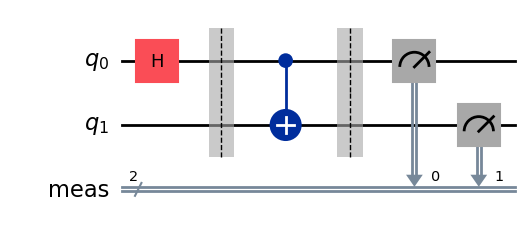

In [20]:
qc = QuantumCircuit(2)
qc.h(0)
qc.barrier()                       # purely structural
qc.cx(0, 1)
qc.measure_all()                   # adds ClassicalRegister 'meas' automatically
print("classical registers:", qc.cregs, "| num_clbits:", qc.num_clbits)
print("barrier counted in size()?  size =", qc.size(), "(h, cx, 2×measure)")
with_b = QuantumCircuit(2); with_b.h(0); with_b.barrier(); with_b.cx(0, 1)
without_b = QuantumCircuit(2); without_b.h(0); without_b.cx(0, 1)
print("unitary with barrier == without barrier:", Operator(with_b) == Operator(without_b), "(it is not a gate)")
qc.draw("mpl")

---
## 9 · The circuit library (`qiskit.circuit.library`)

The study guide points to the **circuit library** page. It contains:

1. **Standard gates** — every gate in §2–§4 (`XGate`, `CXGate`, `RZGate`, `CCXGate` …)
2. **Higher-level gate blocks** — `QFTGate`, `MCXGate`, `PauliEvolutionGate`, `PauliGate`, adders/multipliers, oracles …
3. **Variational circuits** — `n_local`, `efficient_su2`, `real_amplitudes`, `zz_feature_map` … (you meet these with parameterised circuits in Task 3.2)
4. **Data-preparation** circuits and others

> **Qiskit 2.x change.** Many library items used to be *circuit classes* (`QFT`, …) and are now **gate classes** (`QFTGate`, …). The old `QFT` class is **deprecated since 2.1** and will be removed in 3.0 — prefer `QFTGate`.

Classes whose names end in **`Gate`** are applied with `append`; they box a whole algorithmic block into one instruction.

In [21]:
import qiskit.circuit.library as L
gate_classes = sorted(name for name in dir(L) if name.endswith("Gate"))
print(len(gate_classes), "classes ending in 'Gate' in this Qiskit version. A sample:")
print(", ".join(gate_classes[:45]), "...")

94 classes ending in 'Gate' in this Qiskit version. A sample:
AndGate, BitFlipOracleGate, BitwiseXorGate, C3SXGate, C3XGate, C4XGate, CCXGate, CCZGate, CHGate, CPhaseGate, CRXGate, CRYGate, CRZGate, CSGate, CSXGate, CSdgGate, CSwapGate, CU1Gate, CU3Gate, CUGate, CXGate, CYGate, CZGate, DCXGate, DiagonalGate, ECRGate, ExactReciprocalGate, FullAdderGate, GlobalPhaseGate, GraphStateGate, HGate, HalfAdderGate, HamiltonianGate, IGate, InnerProductGate, IntegerComparatorGate, LinearAmplitudeFunctionGate, LinearPauliRotationsGate, MCMTGate, MCPhaseGate, MCU1Gate, MCXGate, MSGate, ModularAdderGate, MultiplierGate ...


In [22]:
# QFTGate: apply a 3-qubit quantum Fourier transform as ONE instruction
qc = QuantumCircuit(3)
qc.append(QFTGate(3), [0, 1, 2])
print("boxed instruction:", qc.count_ops(), "| decomposed:", dict(qc.decompose().count_ops()))

# Check it against the textbook DFT matrix F_jk = ω^{jk}/√N, ω = e^{2πi/N}
N = 8
w = np.exp(2j * np.pi / N)
F = np.array([[w ** (j * k) for k in range(N)] for j in range(N)]) / np.sqrt(N)
print("QFTGate(3) == DFT matrix:", np.allclose(Operator(QFTGate(3)).data, F))

# The inverse is available directly
print("QFT then QFT† = I       :", np.allclose(Operator(QFTGate(3)).data @ Operator(QFTGate(3).inverse()).data, np.eye(N)))

# The Pauli tools from Task 1.1 live here too:
pg = QuantumCircuit(3); pg.append(PauliGate("XZY"), [0, 1, 2])
print("PauliGate('XZY') == Pauli('XZY'):", np.allclose(Operator(pg).data, Pauli("XZY").to_matrix()))

boxed instruction: OrderedDict({'qft': 1}) | decomposed: {'h': 3, 'cp': 3, 'swap': 1}
QFTGate(3) == DFT matrix: True
QFT then QFT† = I       : True
PauliGate('XZY') == Pauli('XZY'): True


---
## 10 · Preview: gates are *abstract* until transpiled

Hardware implements only a **basis gate set**. IBM's superconducting devices use `{rz, sx, x, cx}` (or `cz` / `ecr` on some chips). Anything else is rewritten — a topic that returns in **Task 3.3**. The point for now: every gate in this notebook can be expressed with those few natives, *up to a global phase* (which is physically irrelevant on an uncontrolled circuit).

In [23]:
qc = QuantumCircuit(1); qc.h(0)
t = transpile(qc, basis_gates=["rz", "sx", "x", "cx"], optimization_level=0)
print("H transpiled to native gates:", dict(t.count_ops()))
print(t.draw())
print("same physics (equiv):", Operator(qc).equiv(Operator(t)),
      "| exactly equal:", Operator(qc) == Operator(t),
      "| global_phase carried by circuit:", round(float(t.global_phase), 4))

H transpiled to native gates: {'rz': 2, 'sx': 1}
global phase: π/4
   ┌─────────┐┌────┐┌─────────┐
q: ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├
   └─────────┘└────┘└─────────┘
same physics (equiv): True | exactly equal: True | global_phase carried by circuit: 0.7854


---
## 11 · Gotchas checklist ("what happens if you do it incorrectly")

1. **Removed aliases (Qiskit 2.x):** `cnot`, `toffoli`, `fredkin`, `i`, `u1`, `u2`, `u3`, `cu1`, `cu3`, `bind_parameters` → `AttributeError`. Use `cx`, `ccx`, `cswap`, `id`, `p`/`u`, `cp`/`cu`, `assign_parameters`.
2. **First argument is the control** — `cx(1, 0)` is *not* `cx(0, 1)`. Directional gates: CX, CY, CH, CRX/CRY/CRZ, CU. Symmetric: CZ, CP, SWAP, iSWAP, RZZ, CCZ.
3. **`==` vs `.equiv()`:** `RZ(θ)` and `P(θ)` are `equiv`, not `==`; once controlled they become *genuinely different*.
4. **Broadcasting:** pairs element-wise for two lists, repeats a scalar, errors on mismatched lengths; `append` never broadcasts.
5. **`gate.control(n)` puts the controls first**; `ctrl_state` bit-strings are read little-endian (rightmost bit = first control).
6. **`initialize` includes a reset** (non-unitary) — use `prepare_state` when you need a unitary, or when you will take `Statevector`/`Operator` of the result.
7. **`barrier` is not a gate** — it affects compilation, never the state.
8. **`measure_all()` creates a register named `meas`** — your counts will live under `data.meas`, not `data.c`.
9. **`to_gate()` requires a unitary circuit** — measurements force `to_instruction()`, and instructions cannot be `.control()`led.
10. **Library `QFT` (class) is deprecated** — use `QFTGate`.
11. **Little-endian everywhere:** custom matrices in `qc.unitary`, `ctrl_state`, bit-strings in `Statevector`/counts — qubit 0 is the *rightmost* bit.

---
## 12 · Exercises

### Exercise 1 — SWAP from CNOTs
Build a 2-qubit circuit using **only `cx` gates** that is exactly the `SWAP` gate. (Hint: three CX gates, alternating direction.)

In [24]:
def exercise_1():
    # TODO: return a 2-qubit QuantumCircuit made only of cx gates that equals SwapGate exactly
    return None

ans1 = exercise_1()

In [25]:
def check_1(qc):
    if qc is None: return _todo("Exercise 1")
    assert set(qc.count_ops()) == {"cx"}, f"use only cx gates, found {dict(qc.count_ops())}"
    assert Operator(qc) == Operator(two(SwapGate(), 0, 1)), "unitary is not SWAP"
    print(f"✅ Exercise 1 passed — SWAP = {qc.count_ops()['cx']} CNOTs (this is why SWAPs are expensive on hardware).")
check_1(ans1)

⏳ Exercise 1: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 2 — CZ from H and CX
Using only `h` and `cx`, build a circuit that equals **`cz`** *exactly* (not just up to phase).

In [26]:
def exercise_2():
    # TODO: return a 2-qubit circuit using only h and cx that equals cz(0, 1)
    return None

ans2 = exercise_2()

In [27]:
def check_2(qc):
    if qc is None: return _todo("Exercise 2")
    assert set(qc.count_ops()) <= {"h", "cx"}, f"only h and cx allowed, found {dict(qc.count_ops())}"
    assert Operator(qc) == Operator(two(CZGate(), 0, 1)), "not exactly CZ"
    print("✅ Exercise 2 passed — H on the target turns an X-kick into a Z-kick.")
check_2(ans2)

⏳ Exercise 2: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 3 — predict the broadcast
Without running it, predict the exact list of instructions this code creates, **in order**, as `(name, (qubit indices))` tuples:

```python
qc = QuantumCircuit(5)
qc.h([1, 3])
qc.cx(0, [2, 4])
qc.cz([0, 1], [3, 4])
qc.x(range(2))
```

In [28]:
def exercise_3():
    # TODO: return the list of (gate_name, (qubits...)) tuples in the order they are added
    return None

ans3 = exercise_3()

In [29]:
def check_3(pred):
    if pred is None: return _todo("Exercise 3")
    qc = QuantumCircuit(5)
    qc.h([1, 3]); qc.cx(0, [2, 4]); qc.cz([0, 1], [3, 4]); qc.x(range(2))
    truth = ops(qc)
    assert [tuple(p) for p in pred] == truth, f"expected {truth}"
    print("✅ Exercise 3 passed — broadcasting rules understood.")
check_3(ans3)

⏳ Exercise 3: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 4 — control on zero
Apply an **X to qubit 1 only when qubit 0 is $|0\rangle$**. Return **two** circuits that do it: (a) using `XGate().control(1, ctrl_state=...)` and (b) using only `x` and `cx`.

In [30]:
def exercise_4():
    # TODO: return (circuit_a, circuit_b), both 2-qubit circuits equal to "X on q1 if q0 == 0"
    return None

ans4 = exercise_4()

In [31]:
def check_4(res):
    if res is None: return _todo("Exercise 4")
    target = np.zeros((4, 4))
    # basis index = 2*q1 + q0 ;  q0==0 -> flip q1:  |00>(0) <-> |10>(2),  |01>(1) and |11>(3) unchanged
    target[2, 0] = target[0, 2] = 1; target[1, 1] = target[3, 3] = 1
    for lab, qc in zip("ab", res):
        assert np.allclose(Operator(qc).data, target), f"circuit ({lab}) is wrong"
    print("✅ Exercise 4 passed — both constructions agree.")
check_4(ans4)

⏳ Exercise 4: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 5 — which qubits trigger it? (`ctrl_state` bit order)
Build a 3-qubit circuit where **qubit 2 is flipped only when qubit 0 = 1 *and* qubit 1 = 0**, using `XGate().control(2, ctrl_state=...)` with controls `[0, 1]`. The tricky part is the bit order of `ctrl_state` — use a truth table to check yourself.

In [32]:
def exercise_5():
    # TODO: return a 3-qubit circuit: flip q2 iff (q0 == 1 and q1 == 0)
    return None

ans5 = exercise_5()

In [33]:
def check_5(qc):
    if qc is None: return _todo("Exercise 5")
    for k in range(8):
        q0, q1, q2 = k & 1, (k >> 1) & 1, (k >> 2) & 1
        expected_q2 = q2 ^ (1 if (q0 == 1 and q1 == 0) else 0)
        out = Statevector.from_int(k, 8).evolve(qc)
        j = int(np.argmax(np.abs(out.data)))
        got = (j >> 2) & 1
        assert (j & 3) == (k & 3) and got == expected_q2, f"input |{k:03b}> gave |{j:03b}>"
    print("✅ Exercise 5 passed — ctrl_state is read little-endian (rightmost bit = first control).")
check_5(ans5)

⏳ Exercise 5: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 6 — the exact phase factor
`RZ(θ)` and `P(θ)` differ by a global factor $c$ with `Operator(RZ(θ)) = c · Operator(P(θ))`. For $\theta=1.2$, compute $c$ numerically (don't just copy a formula — derive it from the matrices) and return it as a complex number.

In [34]:
def exercise_6():
    # TODO: return the complex constant c for theta = 1.2
    return None

ans6 = exercise_6()

In [35]:
def check_6(c):
    if c is None: return _todo("Exercise 6")
    th = 1.2
    assert np.allclose(c * PhaseGate(th).to_matrix(), RZGate(th).to_matrix()), "c · P(θ) does not reproduce RZ(θ)"
    print(f"✅ Exercise 6 passed — c = {np.round(c, 4)} = e^(-iθ/2).  Controlled, this factor becomes a real relative phase.")
check_6(ans6)

⏳ Exercise 6: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 7 — wrap and reuse
Create a **gate** named `"flipflop"` on 2 qubits that applies `X` to qubit 0 then `CX(0→1)`. Then build a 4-qubit circuit that applies it to qubit pairs `[0,1]` and `[2,3]`, and return `(gate, big_circuit)`. The big circuit must contain exactly **two** instructions named `flipflop` before decomposition.

In [36]:
def exercise_7():
    # TODO: return (flipflop_gate, big_circuit)
    return None

ans7 = exercise_7()

In [37]:
def check_7(res):
    if res is None: return _todo("Exercise 7")
    gate, big = res
    assert gate.name == "flipflop" and gate.num_qubits == 2, "gate must be named 'flipflop' on 2 qubits"
    assert dict(big.count_ops()) == {"flipflop": 2}, f"expected two boxed instructions, got {dict(big.count_ops())}"
    flat = big.decompose()
    assert dict(flat.count_ops()) == {"x": 2, "cx": 2}, f"decomposed ops wrong: {dict(flat.count_ops())}"
    print("✅ Exercise 7 passed — boxed vs flat is now clear.")
check_7(ans7)

⏳ Exercise 7: not attempted yet — fill in the TODO above and re-run this cell.


### Playground
- Verify with `Operator.equiv`: $T^4=Z$, $\mathrm{SX}^4=I$, $(\mathrm{CX})^2=I$.
- Build `XGate().control(3)` and compare its `.name` with `MCXGate(3).name`.
- Is `RZZ(θ)` equal to `CX · (I⊗RZ(θ)) · CX`? (Try θ = 0.9.)
- Which gates from the catalogue satisfy $U^2 = I$? Loop over `fixed` and test.

In [38]:
# Starter: which fixed single-qubit gates are involutions (U·U = I)?
for name, g in fixed:
    M = g.to_matrix()
    print(f"{name:>5}: U² = I ? {np.allclose(M @ M, np.eye(2))}")

   id: U² = I ? True
    x: U² = I ? True
    y: U² = I ? True
    z: U² = I ? True
    h: U² = I ? True
    s: U² = I ? False
  sdg: U² = I ? False
    t: U² = I ? False
  tdg: U² = I ? False
   sx: U² = I ? False
 sxdg: U² = I ? False


---
## 13 · Exam-style questions

**Q1.** Which call applies the identity gate in Qiskit 2.x?
- A) `qc.i(0)`  B) `qc.id(0)`  C) `qc.iden(0)`  D) `qc.identity(0)`

<details><summary>Answer</summary>

**B.** `qc.i` was removed in 2.0.
</details>

**Q2.** `qc.cx([0, 1], [2, 3])` is equivalent to:
- A) `cx(0,1)`, `cx(2,3)`  B) `cx(0,2)`, `cx(1,3)`  C) `cx(0,2)`, `cx(0,3)`, `cx(1,2)`, `cx(1,3)`  D) an error

<details><summary>Answer</summary>

**B.** Two equal-length lists are paired element-wise.
</details>

**Q3.** `XGate().control(2)` has which name, and what does it do?
- A) `cx` — flips on either control  B) `ccx` — flips only when both controls are 1  C) `cccx`  D) `mcx_gray`

<details><summary>Answer</summary>

**B.** It is the Toffoli gate.
</details>

**Q4.** Which of these is **not** a unitary operation?
- A) `qc.h(0)`  B) `qc.reset(0)`  C) `qc.swap(0,1)`  D) `qc.rz(0.3, 0)`

<details><summary>Answer</summary>

**B.** Reset discards information; it is irreversible.
</details>

**Q5.** `RZ(θ)` versus `P(θ)`:
- A) identical matrices  B) differ by a global phase $e^{-i\theta/2}$  C) differ by a relative phase  D) RZ is not unitary

<details><summary>Answer</summary>

**B.** They are `equiv` but not `==`.
</details>

**Q6.** In the little-endian basis $|q_1q_0\rangle$, `cx(0, 1)` swaps which pair of basis states?
- A) $|00\rangle\leftrightarrow|01\rangle$  B) $|01\rangle\leftrightarrow|11\rangle$  C) $|10\rangle\leftrightarrow|11\rangle$  D) $|01\rangle\leftrightarrow|10\rangle$

<details><summary>Answer</summary>

**B.** Control = qubit 0 (the rightmost bit) must be 1; target qubit 1 flips: $|01\rangle\leftrightarrow|11\rangle$.
</details>

**Q7.** What does `qc.barrier()` do to the circuit's unitary?
- A) inserts an identity gate  B) nothing — it only constrains the transpiler  C) forces a measurement  D) resets qubits

<details><summary>Answer</summary>

**B.**
</details>

**Q8.** Which statement about `qc.initialize(...)` is true?
- A) It is unitary  B) It resets the target qubits first  C) It requires normalised amplitudes **only** on hardware  D) It cannot take a bit-string

<details><summary>Answer</summary>

**B.** Hence `prepare_state` is the unitary alternative.
</details>

**Q9.** The Qiskit 2.x replacement for the deprecated library class `QFT` is:
- A) `qft()`  B) `QFTGate`  C) `FourierGate`  D) `QuantumFourier`

<details><summary>Answer</summary>

**B.**
</details>

**Q10.** `qc.measure_all()` on a circuit with no classical bits:
- A) raises an error  B) adds a register called `meas` and measures all qubits  C) adds a register called `c`  D) measures only active qubits

<details><summary>Answer</summary>

**B.**
</details>

---
## 14 · Solutions & explanations

✅ Exercise 1 passed — SWAP = 3 CNOTs (this is why SWAPs are expensive on hardware).


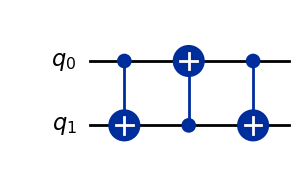

In [39]:
# --- Solution 1: SWAP = CX(0,1) CX(1,0) CX(0,1) -------------------------
sol1 = QuantumCircuit(2)
sol1.cx(0, 1); sol1.cx(1, 0); sol1.cx(0, 1)
check_1(sol1)
# Why: CX(0,1): |a,b> -> |a, a⊕b>.  CX(1,0): -> |a⊕(a⊕b), a⊕b> = |b, a⊕b>.  CX(0,1): -> |b, (a⊕b)⊕b> = |b, a>.
sol1.draw("mpl")

In [40]:
# --- Solution 2: CZ = (I⊗H) CX (I⊗H) -----------------------------------
sol2 = QuantumCircuit(2)
sol2.h(1); sol2.cx(0, 1); sol2.h(1)
check_2(sol2)
# Why: H X H = Z, applied to the target branch that CX would have flipped.

✅ Exercise 2 passed — H on the target turns an X-kick into a Z-kick.

In [41]:
# --- Solution 3 ---------------------------------------------------------
sol3 = [("h", (1,)), ("h", (3,)), ("cx", (0, 2)), ("cx", (0, 4)), ("cz", (0, 3)), ("cz", (1, 4)), ("x", (0,)), ("x", (1,))]
check_3(sol3)
# h([1,3]) → one H per qubit; cx(0,[2,4]) repeats the scalar control; cz([0,1],[3,4]) pairs element-wise; x(range(2)) → X on 0 and 1.

✅ Exercise 3 passed — broadcasting rules understood.


In [42]:
# --- Solution 4 ---------------------------------------------------------
a = QuantumCircuit(2); a.append(XGate().control(1, ctrl_state=0), [0, 1])
b = QuantumCircuit(2); b.x(0); b.cx(0, 1); b.x(0)
check_4((a, b))
# Open control = ordinary control sandwiched between X gates on the control qubit.

✅ Exercise 4 passed — both constructions agree.


In [43]:
# --- Solution 5 ---------------------------------------------------------
sol5 = QuantumCircuit(3)
sol5.append(XGate().control(2, ctrl_state="01"), [0, 1, 2])
check_5(sol5)
# ctrl_state "01": rightmost bit (1) ↔ first control (q0 must be 1); next bit (0) ↔ second control (q1 must be 0).
# A frequent wrong answer is "10", which triggers on q0=0, q1=1.

✅ Exercise 5 passed — ctrl_state is read little-endian (rightmost bit = first control).


In [44]:
# --- Solution 6 ---------------------------------------------------------
th = 1.2
sol6 = RZGate(th).to_matrix()[0, 0] / PhaseGate(th).to_matrix()[0, 0]
check_6(complex(sol6))
print("e^(-iθ/2) =", np.round(np.exp(-1j * th / 2), 4))

✅ Exercise 6 passed — c = (0.8253-0.5646j) = e^(-iθ/2).  Controlled, this factor becomes a real relative phase.
e^(-iθ/2) = (0.8253-0.5646j)


✅ Exercise 7 passed — boxed vs flat is now clear.

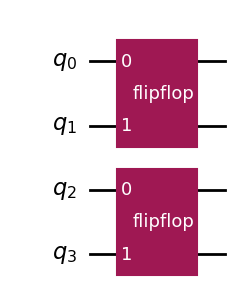

In [45]:
# --- Solution 7 ---------------------------------------------------------
sub = QuantumCircuit(2, name="flipflop"); sub.x(0); sub.cx(0, 1)
g = sub.to_gate()
big7 = QuantumCircuit(4); big7.append(g, [0, 1]); big7.append(g, [2, 3])
check_7((g, big7))
big7.draw("mpl")

---
## 15 · One-page summary

- **Apply a gate:** `qc.<method>(…)` (broadcasts) or `qc.append(GateObject(), qubits)` (never broadcasts, works for everything).
- **Inspect:** `qc.data`, `qc.count_ops()`, `qc.size()`, `qc.depth()`, `qc.width()`, `Operator(qc)`.
- **Catalogue:** fixed (`id x y z h s sdg t tdg sx sxdg`), parameterised (`rx ry rz p u r`), two-qubit (`cx cy cz ch cp crx cry crz cu swap iswap ecr dcx rxx ryy rzz rzx`), three-qubit (`ccx ccz cswap`), `mcx`.
- **Equality:** `==` exact, `.equiv()` up to global phase. `RZ(θ)` = $e^{-i\theta/2}P(\theta)$.
- **Order:** first qubit argument is the control; `ctrl_state` and all bit-strings are little-endian.
- **Transform:** `.inverse()`, `.power(k)`, `.control(n, ctrl_state=…)`, `qc.to_gate()`, `qc.compose()`, `qc.decompose()`.
- **Non-unitary:** `measure`, `reset`, `initialize`, `delay`; `barrier` is structural only.
- **Qiskit 2.x:** removed `cnot/toffoli/fredkin/i/u1/u2/u3`; `QFT` → `QFTGate`.
- **Next:** Section 2 — visualising circuits, measurements and states (Tasks 2.1–2.3).